# Visualize Dataset

In [6]:
from torchvision import transforms as pth_transforms
from torchvision import datasets
import torch
from torch.utils.data import DataLoader, random_split
from torchmetrics.classification import MulticlassConfusionMatrix, MulticlassAccuracy
import matplotlib.pyplot as plt
import torchvision

In [7]:
# Setting seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [10]:
# Construct datasets, dataloaders

transform = pth_transforms.Compose(
    [
        pth_transforms.Resize(224),
        pth_transforms.ToTensor(),
        pth_transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
    ]
)

denormalize = pth_transforms.Compose(
    [
        pth_transforms.Normalize(mean=[0.0, 0.0, 0.0], std=[1 / 0.229, 1 / 0.224, 1 / 0.225]),
        pth_transforms.Normalize(mean=[-0.485, -0.456, -0.406], std=[1.0, 1.0, 1.0]),
    ]
)


my_dataset = datasets.ImageFolder(root="dl_action_dataset", transform=transform)
NUM_CLASSES = len(my_dataset.classes)

# Split the dataset in train, validation and test set

SPLIT_RATIO = [0.7, 0.15, 0.15]

train_size = int(SPLIT_RATIO[0] * len(my_dataset))
val_size = int(SPLIT_RATIO[1] * len(my_dataset))
test_size = len(my_dataset) - train_size - val_size
_, _, test_dataset = random_split(my_dataset, [train_size, val_size, test_size])


In [11]:
my_dataset.classes

['cut', 'pour', 'slide', 'stir']

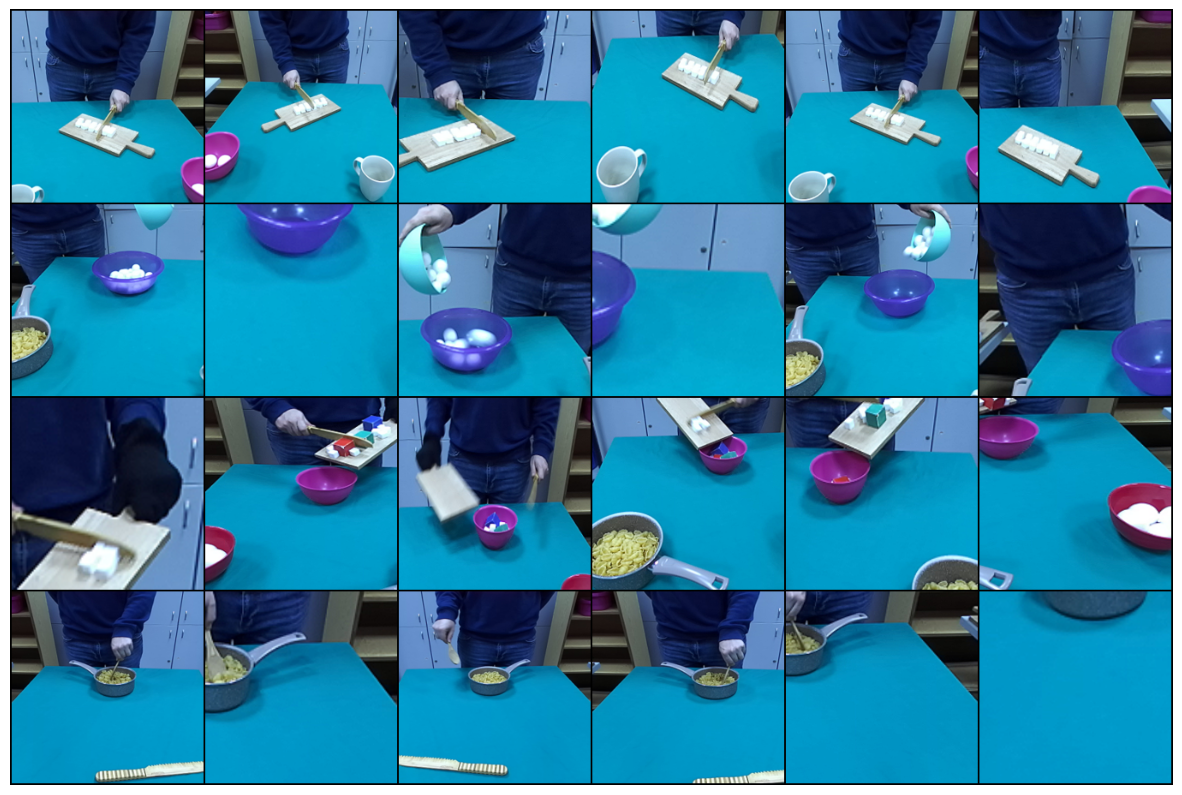

In [17]:
# Pick N images from each class for visualization
N = 6
samples = {}

# after transform
h, w = 224, 224

for c in range(NUM_CLASSES):
    samples[c] = []
    for i in range(len(my_dataset)):
        if my_dataset[i][1] == c:
            samples[c].append(denormalize(my_dataset[i][0]))
        if len(samples[c]) == N:
            break



grid = torchvision.utils.make_grid(torch.cat([torch.stack(samples[c]) for c in range(NUM_CLASSES)]), nrow=N )
plt.figure(figsize=(15, 15))
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.show()


# Visualize with Grad-CAM

In [12]:
import os
from utils import reshape_transform

import torch

import numpy as np
import cv2
import requests
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image, \
    deprocess_image, \
    preprocess_image
from PIL import Image

In [13]:
# Load pretrained model

import timm
NUM_CLASSES = 4
model = timm.create_model('vit_base_patch16_224', pretrained=True)
model.head = torch.nn.Linear(model.head.in_features, NUM_CLASSES)


model.load_state_dict(torch.load('best_model.pth'))
model.eval()
print("Model loaded successfully!")

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False)
        (norm): Identity(

In [35]:

def get_grad_cam(img, class_idx):
    img = img.resize((224, 224))
    img = np.float32(img) / 255
    input_tensor = preprocess_image(img, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    # The target for the CAM is the Bear category.
    # As usual for classication, the target is the logit output
    # before softmax, for that category.

    targets = [ClassifierOutputTarget(class_idx)]
    # target_layers = [model.layer4]
    target_layers = [model.blocks[-1].norm1]
    with GradCAM(model=model, target_layers=target_layers, reshape_transform=reshape_transform) as cam:
        grayscale_cams = cam(input_tensor=input_tensor, targets=targets, aug_smooth=True, eigen_smooth=True)
        cam_image = show_cam_on_image(img, grayscale_cams[0, :], use_rgb=True)
    cam = np.uint8(255*grayscale_cams[0, :])
    cam = cv2.merge([cam, cam, cam])
    images = np.hstack((np.uint8(255*img), cam_image))
    return Image.fromarray(images)




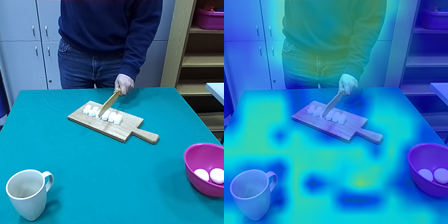

In [36]:
img = Image.open('dl_action_dataset/cut/00002.png')
ret=get_grad_cam(img, my_dataset.classes.index('cut'))
ret

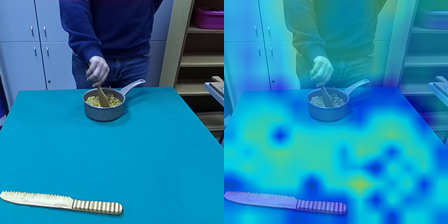

In [37]:
img = Image.open('dl_action_dataset/stir/00008.png')
ret=get_grad_cam(img, my_dataset.classes.index('stir'))
ret